# Company Brain: results analysis

This notebook summarises the project's tests: choosing the model by memory, comparing embedding models, and the quality evaluation in English and Spanish. It reads the files in `reports/`, which the system writes itself.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

REPORTS = Path('..') / 'reports'
plt.rcParams['figure.figsize'] = (9, 4)

## 1. Memory chooses the model

Qwen3.5-4B measured with the embedding model and the reranker loaded, Chrome closed. The design limit is 14 GB of memory used with no critical memory pressure. The 9B and 12B models exceeded the limit and were dropped.

In [2]:
bench = pd.read_csv(REPORTS / 'benchmark_full.csv')
bench['peak_GB'] = bench['peak_memory_bytes'] / 1e9
summary = bench[bench['cold'] == 'no'].groupby('mode').agg(
    median_seconds=('total_s', 'median'), peak_GB=('peak_GB', 'max'), pressure=('peak_pressure', 'max'))
summary.round(1)

,median_seconds,peak_GB,pressure
mode,,,
answer,8.1,14.4,normal
draft,44.6,14.1,normal
summarise,179.3,15.2,warning


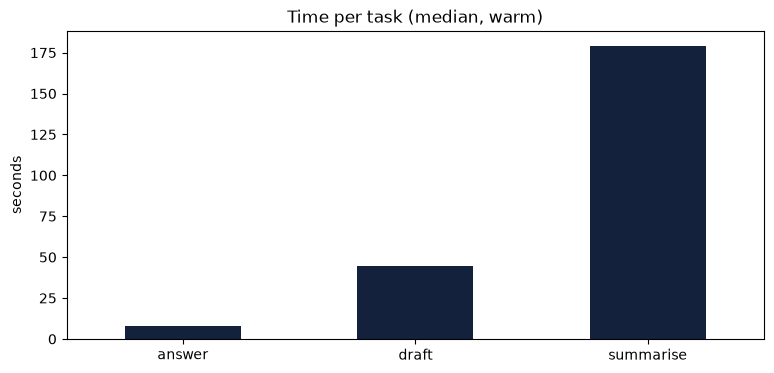

In [3]:
ax = summary['median_seconds'].plot.bar(color='#14213D', rot=0)
ax.set_ylabel('seconds'); ax.set_xlabel('')
ax.set_title('Time per task (median, warm)')
plt.show()

## 2. Embedding models

Three candidates on the 30 retrieval questions (15 EN, 15 ES), 500-token chunks, reranker on. All find the right passage in the top 5; EmbeddingGemma 2 is the fastest.

In [4]:
stage1 = json.loads((REPORTS / 'tuning' / 'stage1.json').read_text())
emb = pd.DataFrame([{
    'embedding': r['config']['embedding'],
    'recall@5': r['recall@5'],
    'MRR': round(r['mrr'], 3),
    'seconds per search': round(r['seconds'], 2),
} for r in stage1['results']])
emb

,embedding,recall@5,MRR,seconds per search
0,qwen3-embedding:0.6b,1.0,0.967,0.52
1,bge-m3:latest,1.0,0.967,0.31
2,embeddinggemma-2:270m,1.0,0.967,0.24


## 3. Answer quality

Latest full evaluation on the 44 tuning questions, with the LLM judge (Gemma 4 12B).

In [5]:
runs = pd.read_csv(REPORTS / 'eval_runs.csv')
last_id = runs.loc[runs['stage'] == 'stage4', 'run_id'].iloc[-1]
last = runs[runs['run_id'] == last_id]
table = last.pivot_table(index='metric', columns='language', values='value', aggfunc='last')
print('Run:', last_id)
table[['en', 'es', 'all']].round(2)

Run: 20261104-115538-f31c0d


language,en,es,all
metric,,,
adversarial,0.50,1.00,0.75
answer_relevancy,0.63,0.77,0.71
citation_support,0.93,0.90,0.91
evidence_coverage,1.00,1.00,1.00
fact_correct,1.00,0.92,0.96
faithfulness,0.86,0.91,0.89
hard_blockers,NaN,NaN,0.00
mrr,0.87,0.97,0.92
questions_passed,0.91,0.95,0.93


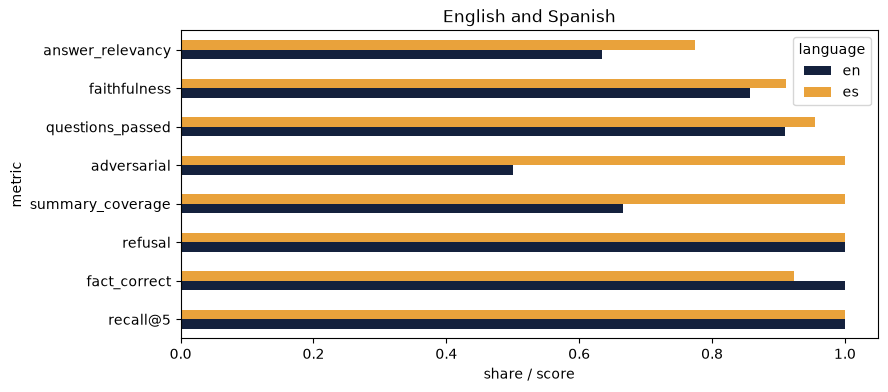

In [6]:
show = ['recall@5', 'fact_correct', 'refusal', 'summary_coverage', 'adversarial', 'questions_passed', 'faithfulness', 'answer_relevancy']
ax = table.loc[show, ['en', 'es']].plot.barh(color=['#14213D', '#E9A23B'])
ax.set_xlim(0, 1.05); ax.set_xlabel('share / score')
ax.set_title('English and Spanish')
plt.show()

## 4. Final exam: the 22 locked questions

Run once on 6 November 2026 with the frozen configuration (`config/selected.toml`). Only aggregates are stored; the questions stay encrypted. Report: `reports/final_eval.md`.

In [7]:
final = runs[runs['split'] == 'locked']
targets = {'recall@5': 0.85, 'mrr': 0.70, 'faithfulness': 0.90, 'answer_relevancy': 0.80,
           'citation_validity': 1.00, 'refusal': 0.90}
exam = final.pivot_table(index='metric', columns='language', values='value', aggfunc='last')[['en', 'es', 'all']]
exam['target'] = exam.index.map(targets)
exam.round(2)

language,en,es,all,target
metric,,,,
adversarial,0.00,0.00,0.00,NaN
answer_relevancy,0.75,0.65,0.70,0.80
citation_support,0.88,0.86,0.87,NaN
citation_validity,1.00,1.00,1.00,1.00
evidence_coverage,0.88,1.00,0.94,NaN
fact_correct,0.86,0.86,0.86,NaN
faithfulness,0.73,0.87,0.80,0.90
hard_blockers,NaN,NaN,0.00,NaN
mrr,0.94,0.94,0.94,0.70


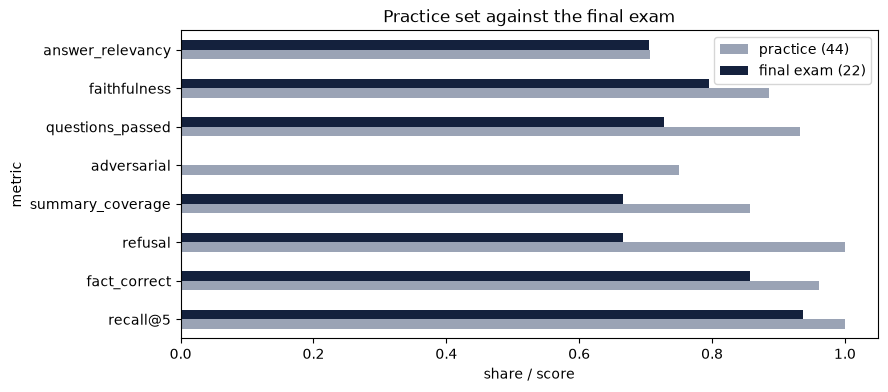

In [8]:
compare = pd.DataFrame({'practice (44)': table['all'], 'final exam (22)': exam['all']}).dropna()
ax = compare.loc[[m for m in show if m in compare.index]].plot.barh(color=['#9AA3B5', '#14213D'])
ax.set_xlim(0, 1.05); ax.set_xlabel('share / score')
ax.set_title('Practice set against the final exam')
plt.show()

## 5. Blind human rating

The owner scored 20 answers from 1 to 5 without knowing which configuration wrote them.

In [9]:
ratings = pd.read_csv(REPORTS / 'blind_ratings_unblinded.csv')
ratings.groupby('language')['score'].agg(['count', 'mean']).round(2)

,count,mean
language,,
en,10,4.9
es,10,4.7


## 6. Over time

Questions passed in each full evaluation on the practice set.

In [10]:
passed = runs[(runs['metric'] == 'questions_passed') & (runs['language'] == 'all') & (runs['split'] == 'tuning')]
passed[['date', 'stage', 'count', 'total', 'value']].drop_duplicates('date').reset_index(drop=True)

,date,stage,count,total,value
0,2026-10-24 15:37,baseline,35,44,0.7955
1,2026-10-24 15:59,baseline,41,44,0.9318
2,2026-10-24 17:00,baseline-judged,41,44,0.9318
3,2026-10-25 21:10,stage4,41,44,0.9318
4,2026-11-04 12:01,stage4,41,44,0.9318


## Conclusions

- On a 16 GB laptop, memory decides the model: a 4B model with good context is enough.
- Retrieval is the solid part (recall@5 100% in practice, 94% in the final exam).
- The final exam passed 16 of 22 (73%) against 41 of 44 in practice: the drop is what an unseen set is for. The verdict is "pilot, below target": good for drafts a person reviews.
- The safety rules held: no figure without its source and no client mixing (0 hard blockers).
- Weak points: planted instructions (0 of 2 resisted in the exam), relevance (0.70) and English faithfulness (0.73).
- With few documents, RAG is a better bet than fine-tuning, which is the next step.